# Name - Swatej Sonawane
# Github Username - swatejsonawane18
# USC ID - 9314761761

References - 

https://www.geeksforgeeks.org/random-forest-classifier-using-scikit-learn/
https://machinelearningmastery.com/smote-oversampling-for-imbalanced-classification/
https://www.analyticsvidhya.com/blog/2021/06/5-techniques-to-handle-imbalanced-data-for-a-classification-problem/
https://www.datatechnotes.com/2019/07/classification-example-with.html
https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html

In [1]:
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import tree,metrics
from sklearn.model_selection import cross_val_score,KFold,RepeatedKFold,GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,roc_curve,auc
from sklearn.linear_model import LassoCV
import regex
from sklearn.metrics import RocCurveDisplay
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier,XGBRegressor
import warnings

# Q1 a

In [2]:
df_train = pd.read_csv(r"../data/aps_failure_training_set.csv" ,sep=",")
df_test = pd.read_csv(r"../data/aps_failure_test_set.csv")

In [3]:
df_test

,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,60,0,20,12,0,0,0,0,0,...,1098,138,412,654,78,88,0,0,0,0
1,neg,82,0,68,40,0,0,0,0,0,...,1068,276,1620,116,86,462,0,0,0,0
2,neg,66002,2,212,112,0,0,0,0,0,...,495076,380368,440134,269556,1315022,153680,516,0,0,0
3,neg,59816,na,1010,936,0,0,0,0,0,...,540820,243270,483302,485332,431376,210074,281662,3232,0,0
4,neg,1814,na,156,140,0,0,0,0,0,...,7646,4144,18466,49782,3176,482,76,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15995,neg,81852,na,2130706432,892,0,0,0,0,0,...,632658,273242,510354,373918,349840,317840,960024,25566,0,0
15996,neg,18,0,52,46,8,26,0,0,0,...,266,44,46,14,2,0,0,0,0,0
15997,neg,79636,na,1670,1518,0,0,0,0,0,...,806832,449962,778826,581558,375498,222866,358934,19548,0,0
15998,neg,110,na,36,32,0,0,0,0,0,...,588,210,180,544,1004,1338,74,0,0,0


In [4]:
df_train

,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,na,2130706438,280,0,0,0,0,0,...,1240520,493384,721044,469792,339156,157956,73224,0,0,0
1,neg,33058,na,0,na,0,0,0,0,0,...,421400,178064,293306,245416,133654,81140,97576,1500,0,0
2,neg,41040,na,228,100,0,0,0,0,0,...,277378,159812,423992,409564,320746,158022,95128,514,0,0
3,neg,12,0,70,66,0,10,0,0,0,...,240,46,58,44,10,0,0,0,4,32
4,neg,60874,na,1368,458,0,0,0,0,0,...,622012,229790,405298,347188,286954,311560,433954,1218,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59995,neg,153002,na,664,186,0,0,0,0,0,...,998500,566884,1290398,1218244,1019768,717762,898642,28588,0,0
59996,neg,2286,na,2130706538,224,0,0,0,0,0,...,10578,6760,21126,68424,136,0,0,0,0,0
59997,neg,112,0,2130706432,18,0,0,0,0,0,...,792,386,452,144,146,2622,0,0,0,0
59998,neg,80292,na,2130706432,494,0,0,0,0,0,...,699352,222654,347378,225724,194440,165070,802280,388422,0,0


In [5]:
df_test.dtypes

class     object
aa_000     int64
ab_000    object
ac_000    object
ad_000    object
           ...  
ee_007    object
ee_008    object
ee_009    object
ef_000    object
eg_000    object
Length: 171, dtype: object

# Q1 b i

Some common data imputation techniques are:

Mean/median imputation: This method involves replacing missing values with the mean or median of the available data.

Regression imputation: Regression imputation involves using regression analysis to predict missing values based on the relationships between the missing values and other variables in the dataset.

K-nearest neighbor imputation: This technique involves finding the k-nearest neighbors to the observation with missing values, and then using the values of these neighbors to impute the missing value.

Multiple imputation: This method involves generating multiple plausible imputations for missing values, and then analyzing each imputed dataset separately.

Last observation carried forward (LOCF): This method involves using the last available observation for a variable to impute missing values that occur later in the dataset.

Hot deck imputation: This technique involves selecting a donor record that has a similar set of values to the record with missing values and imputing the missing value with the value from the donor record.

I am using Mean imputation.

In [6]:
df_train=df_train.replace('na',np.nan)
df_test=df_test.replace('na',np.nan)

In [7]:
df_train=df_train.replace(np.nan,df_train.mean(numeric_only=True))
df_test=df_test.replace(np.nan,df_test.mean(numeric_only=True))
df_train=df_train.fillna(0) 
df_test=df_test.fillna(0)     

In [8]:
df_test

,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,60,0,20,12,0,0,0,0,0,...,1098,138,412,654,78,88,0,0,0,0
1,neg,82,0,68,40,0,0,0,0,0,...,1068,276,1620,116,86,462,0,0,0,0
2,neg,66002,2,212,112,0,0,0,0,0,...,495076,380368,440134,269556,1315022,153680,516,0,0,0
3,neg,59816,0,1010,936,0,0,0,0,0,...,540820,243270,483302,485332,431376,210074,281662,3232,0,0
4,neg,1814,0,156,140,0,0,0,0,0,...,7646,4144,18466,49782,3176,482,76,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15995,neg,81852,0,2130706432,892,0,0,0,0,0,...,632658,273242,510354,373918,349840,317840,960024,25566,0,0
15996,neg,18,0,52,46,8,26,0,0,0,...,266,44,46,14,2,0,0,0,0,0
15997,neg,79636,0,1670,1518,0,0,0,0,0,...,806832,449962,778826,581558,375498,222866,358934,19548,0,0
15998,neg,110,0,36,32,0,0,0,0,0,...,588,210,180,544,1004,1338,74,0,0,0


In [9]:
df_train

,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,0,2130706438,280,0,0,0,0,0,...,1240520,493384,721044,469792,339156,157956,73224,0,0,0
1,neg,33058,0,0,0,0,0,0,0,0,...,421400,178064,293306,245416,133654,81140,97576,1500,0,0
2,neg,41040,0,228,100,0,0,0,0,0,...,277378,159812,423992,409564,320746,158022,95128,514,0,0
3,neg,12,0,70,66,0,10,0,0,0,...,240,46,58,44,10,0,0,0,4,32
4,neg,60874,0,1368,458,0,0,0,0,0,...,622012,229790,405298,347188,286954,311560,433954,1218,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59995,neg,153002,0,664,186,0,0,0,0,0,...,998500,566884,1290398,1218244,1019768,717762,898642,28588,0,0
59996,neg,2286,0,2130706538,224,0,0,0,0,0,...,10578,6760,21126,68424,136,0,0,0,0,0
59997,neg,112,0,2130706432,18,0,0,0,0,0,...,792,386,452,144,146,2622,0,0,0,0
59998,neg,80292,0,2130706432,494,0,0,0,0,0,...,699352,222654,347378,225724,194440,165070,802280,388422,0,0


In [10]:
for col in df_train.columns:
    if col!='class':
        df_train[col]=(df_train[col]).astype(float)
        df_test[col]=(df_test[col]).astype(float)

In [11]:
df_test.dtypes

class      object
aa_000    float64
ab_000    float64
ac_000    float64
ad_000    float64
           ...   
ee_007    float64
ee_008    float64
ee_009    float64
ef_000    float64
eg_000    float64
Length: 171, dtype: object

# Q1 b ii

In [12]:
coef_of_var = df_train.std()/df_train.mean(numeric_only=None)
print(coef_of_var)

C:\Users\Swatej Sonawane\AppData\Local\Temp\ipykernel_41556\1114173704.py:1: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  coef_of_var = df_train.std()/df_train.mean(numeric_only=None)


aa_000      2.450938
ab_000     10.383494
ac_000      2.310241
ad_000    244.375986
ae_000     24.200137
             ...    
ee_007      5.019734
ee_008      3.260186
ee_009      5.691612
ef_000     49.366659
eg_000     42.481747
Length: 170, dtype: float64


# Q1 b iii

<AxesSubplot:>

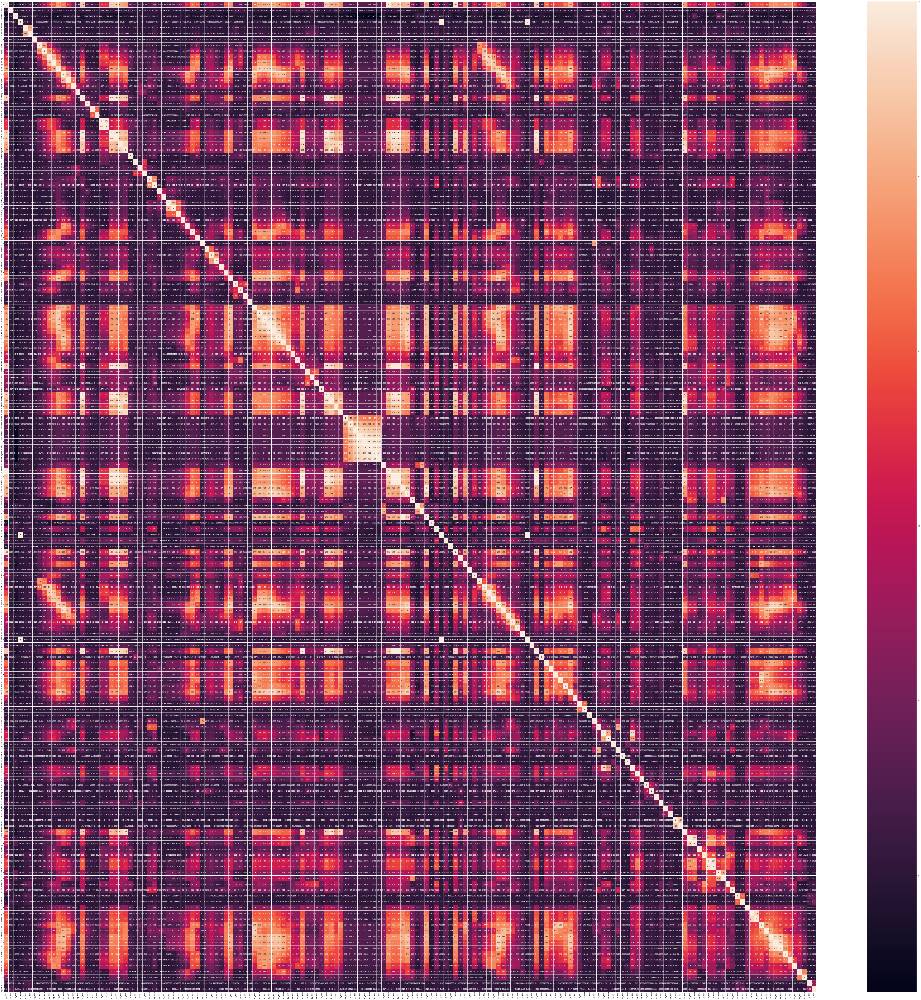

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(123,123))      
sns.heatmap(df_train.corr(), annot=True, linewidths=.5, ax=ax)

In [14]:
df_signif_attributes = pd.DataFrame(coef_of_var)
df_signif_attributes  = df_signif_attributes.reset_index()
df_signif_attributes = df_signif_attributes.rename(columns={'index':'feature',0:'CV'})

df_signif_attributes = df_signif_attributes.sort_values(by="CV",ascending=False).reset_index(drop=True)
print(df_signif_attributes)

    feature          CV
0    cf_000  244.888364
1    co_000  244.510765
2    ad_000  244.375986
3    cs_009  237.930554
4    dh_000  123.216097
..      ...         ...
165  bk_000    1.425606
166  bs_000    1.063863
167  ca_000    1.013615
168  cb_000    0.922851
169  cd_000    0.106748

[170 rows x 2 columns]


# Q1 b iv

In [15]:
n_sigif_attributes = math.floor(math.sqrt(170))
df_signif_attributes=df_signif_attributes.iloc[:n_sigif_attributes]
print(df_signif_attributes)

   feature          CV
0   cf_000  244.888364
1   co_000  244.510765
2   ad_000  244.375986
3   cs_009  237.930554
4   dh_000  123.216097
5   dj_000  117.494225
6   ag_000   92.917755
7   as_000   87.332500
8   ay_009   84.733735
9   ak_000   80.424975
10  az_009   77.838544
11  ch_000   77.453857
12  au_000   68.882751


       cf_000  co_000  ad_000  cs_009  dh_000  dj_000  ag_000  as_000  ay_009  \
0         2.0   220.0   280.0     0.0     0.0     0.0     0.0     0.0     0.0   
1         0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0   
2         0.0     0.0   100.0     0.0     0.0     0.0     0.0     0.0     0.0   
3         2.0     2.0    66.0     0.0     0.0     0.0     0.0     0.0     0.0   
4         0.0   202.0   458.0     0.0     0.0     0.0     0.0     0.0     0.0   
...       ...     ...     ...     ...     ...     ...     ...     ...     ...   
59995     0.0   224.0   186.0     0.0     0.0     0.0     0.0     0.0     0.0   
59996     2.0     0.0   224.0     0.0     0.0     0.0     0.0     0.0     0.0   
59997     2.0     0.0    18.0     0.0     0.0     0.0     0.0     0.0     0.0   
59998     2.0   580.0   494.0     0.0   190.0     0.0     0.0     0.0     0.0   
59999     0.0     6.0   628.0     0.0     0.0     0.0     0.0     0.0     0.0   

       ak_000  az_009  ch_0

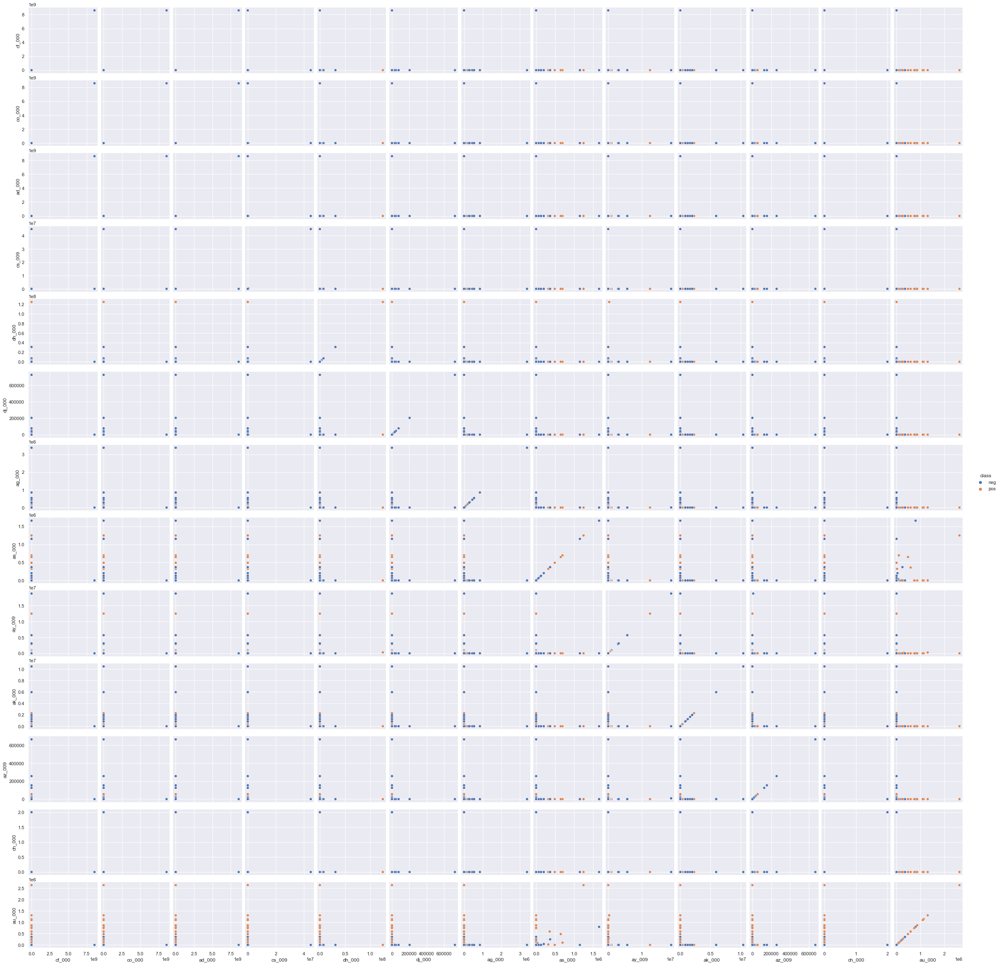

In [16]:
sns.set()
signif_features=df_signif_attributes['feature']
signif_df_train=df_train[signif_features]

signif_df_train.insert(len(signif_df_train.columns),'class',df_train['class'])
print(signif_df_train)
sns.pairplot(signif_df_train,hue="class",height=2.5,diag_kind=None)

<AxesSubplot:>

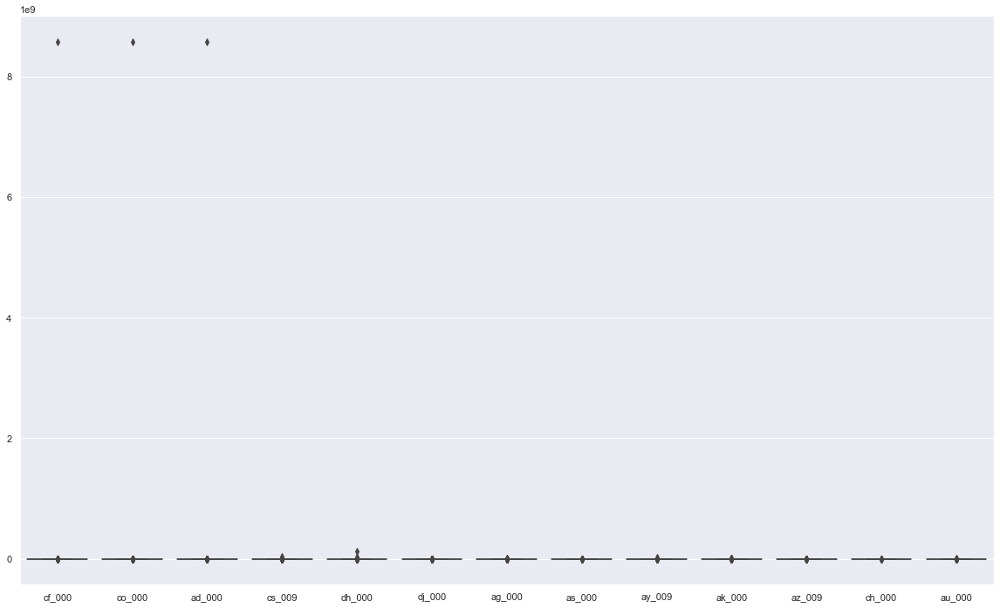

In [17]:
import matplotlib.pyplot as plt
fig = plt.gcf()

fig.set_size_inches(20, 12)
sns.boxplot(data=signif_df_train)

# Q1 b v

In [18]:
print(df_train['class'].value_counts())

neg    59000
pos     1000
Name: class, dtype: int64


# Q1 c

In [19]:
df_train=df_train.replace({'class':{'pos':1,'neg':0}})
df_test=df_test.replace({'class':{'pos':1,'neg':0}})
y_train = df_train['class']
y_test = df_test['class']
x_train = df_train.iloc[:,1:]
x_test = df_test.iloc[:,1:]

clf = RandomForestClassifier(oob_score=True)
clf.fit(x_train,y_train)
y_test_pred = clf.predict(x_test)
y_train_pred = clf.predict(x_train)
oob_error = 1 - clf.oob_score_

In [20]:
oob_error

0.0062833333333333075

In [21]:
1-clf.score(x_test,y_test)

0.00737500000000002

In [22]:
confusion_matrix(y_test,y_test_pred)

array([[15607,    18],
       [  100,   275]], dtype=int64)

In [23]:
confusion_matrix(y_train,y_train_pred)

array([[59000,     0],
       [    0,  1000]], dtype=int64)

In [24]:
tn,fp,fn,tp = confusion_matrix(y_test,y_test_pred).ravel()
mr = (fp+fn) / (tn+tp+fn+fp)
print(f'Misclassification test rate = {mr*100}%\n')

Misclassification test rate = 0.7374999999999999%



In [25]:
tn,fp,fn,tp = confusion_matrix(y_train,y_train_pred).ravel()
mr = (fp+fn) / (tn+tp+fn+fp)
print(f'Misclassification train rate = {mr*100}%\n')

Misclassification train rate = 0.0%



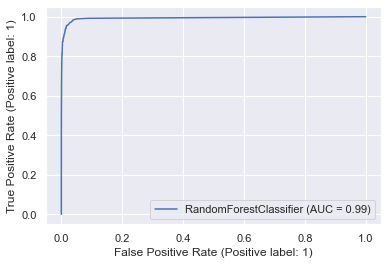

In [26]:
RocCurveDisplay.from_estimator(clf, x_test, y_test)

AUC is 0.99, from the graph above.

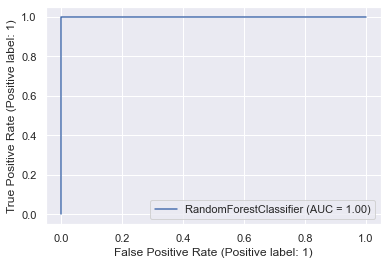

In [27]:
RocCurveDisplay.from_estimator(clf, x_train, y_train)

AUC is 1.00, from the graph above.

# Q1 d

1. Upsample or Downsample the minority or majority class.
2. SMOTE - It looks into minority class instances and use k nearest neighbor to select a random nearest neighbor, and a synthetic instance is created randomly in feature space.
3. Threshold moving - Change the threshold to the optimum value so that it can efficiently separate two classes. We can use ROC Curves and Precision-Recall Curves to find the optimal threshold for the classifier.


In [28]:
bal_model = SMOTE()
x_train_bal, y_train_bal = bal_model.fit_resample(x_train,y_train)
clf_bal = RandomForestClassifier()
clf_bal.fit(x_train_bal,y_train_bal)
y_pred_bal = clf_bal.predict(x_test)

In [29]:
confusion_matrix(y_test,y_pred_bal)

array([[15551,    74],
       [   63,   312]], dtype=int64)

In [30]:
tn1,fp1,fn1,tp1 = confusion_matrix(y_test,y_pred_bal).ravel()

mr_bal = (fp1+fn1) / (tn1+tp1+fn1+fp1)
print(f'Misclassification rate = {mr_bal*100}%\n')

Misclassification rate = 0.8562500000000001%



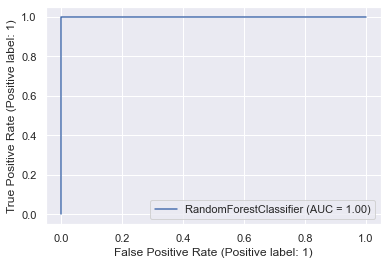

In [31]:
RocCurveDisplay.from_estimator(clf_bal, x_train_bal, y_train_bal)

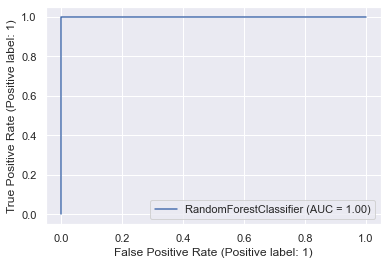

In [32]:
RocCurveDisplay.from_estimator(clf_bal, x_train, y_train)

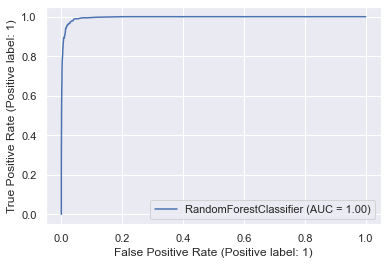

In [33]:
RocCurveDisplay.from_estimator(clf_bal, x_test, y_test)

# Q1 e

In [34]:
warnings.filterwarnings(action='ignore')
xgb = XGBClassifier(objective='binary:logistic')
params = { 
          'alpha':np.linspace(0.1,1,10)
         }
grid = GridSearchCV(estimator=xgb,param_grid=params,verbose=True)
grid_mod=grid.fit(x_train,y_train,eval_metric='rmse')

print('best_alpha :',grid.best_params_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
best_alpha : {'alpha': 0.30000000000000004}


In [35]:
best_alpha = 0.3
xg = XGBClassifier(objective='binary:logistic',alpha=best_alpha)
xg.fit(x_train,y_train,eval_metric='rmse')
xg_pred_test = xg.predict(x_test)
xg_pred_train = xg.predict(x_train)

In [36]:
confusion_matrix(y_test,xg_pred_test)

array([[15610,    15],
       [   81,   294]], dtype=int64)

In [37]:
confusion_matrix(y_train,xg_pred_train)

array([[59000,     0],
       [    1,   999]], dtype=int64)

In [38]:
tn2,fp2,fn2,tp2 = confusion_matrix(y_train,xg_pred_train).ravel()
xg_bal_train = (fp2+fn2) / (tn2+tp2+fn2+fp2)
print(f'Misclassification rate = {xg_bal_train*100}%\n')

Misclassification rate = 0.0016666666666666668%



In [39]:
tn2,fp2,fn2,tp2 = confusion_matrix(y_test,xg_pred_test).ravel()
xg_bal_test = (fp2+fn2) / (tn2+tp2+fn2+fp2)
print(f'Misclassification rate = {xg_bal_test*100}%\n')


Misclassification rate = 0.6%



In [40]:
1-xg.score(x_test,y_test)

0.006000000000000005

In [41]:
1-xg.score(x_train,y_train)

1.666666666666483e-05

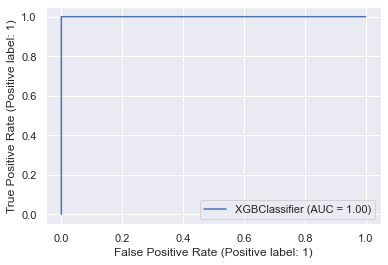

In [42]:
RocCurveDisplay.from_estimator(xg, x_train, y_train)

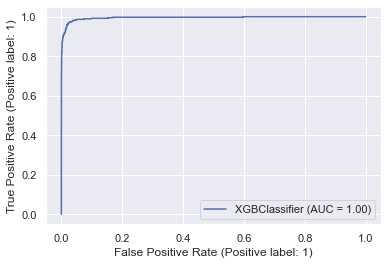

In [43]:
RocCurveDisplay.from_estimator(xg, x_test, y_test)

# Q1 f

In [44]:
xgb_smote = XGBClassifier(objective='binary:logistic', alpha=best_alpha)
xgb_smote.fit(x_train_bal, y_train_bal,eval_metric='rmse')
xgb_smote_pred = xgb_smote.predict(x_test)

In [45]:
1-xgb_smote.score(x_test,y_test)

0.0068749999999999645

In [46]:
confusion_matrix(y_test,xgb_smote_pred)

array([[15576,    49],
       [   61,   314]], dtype=int64)

In [47]:
tn3,fp3,fn3,tp3 = confusion_matrix(y_test,xgb_smote_pred).ravel()
mr3 = (fp3+fn3) / (tn3+tp3+fn3+fp3)
print(f'Misclassification rate = {mr3*100}%\n')


Misclassification rate = 0.6875%



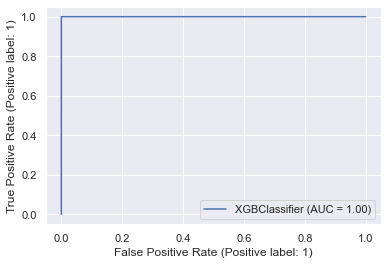

In [48]:
RocCurveDisplay.from_estimator(xgb_smote, x_train, y_train)

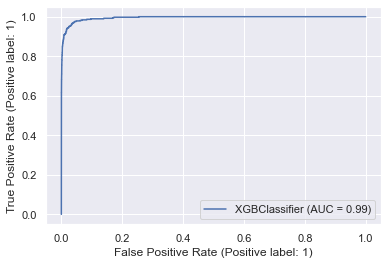

In [49]:
RocCurveDisplay.from_estimator(xgb_smote, x_test, y_test)

Thus, the uncompensated model has a lesser test error as compared to SMOTE model.

Q2

a  - (i) Decrease steadily.


b  - (ii) Decrease initially, and then eventually start increasing in a U shape.

c  - (iii) Steadily increase.

d  - (iv) Steadily decrease.

e  - (v) Remains constant.

Q3

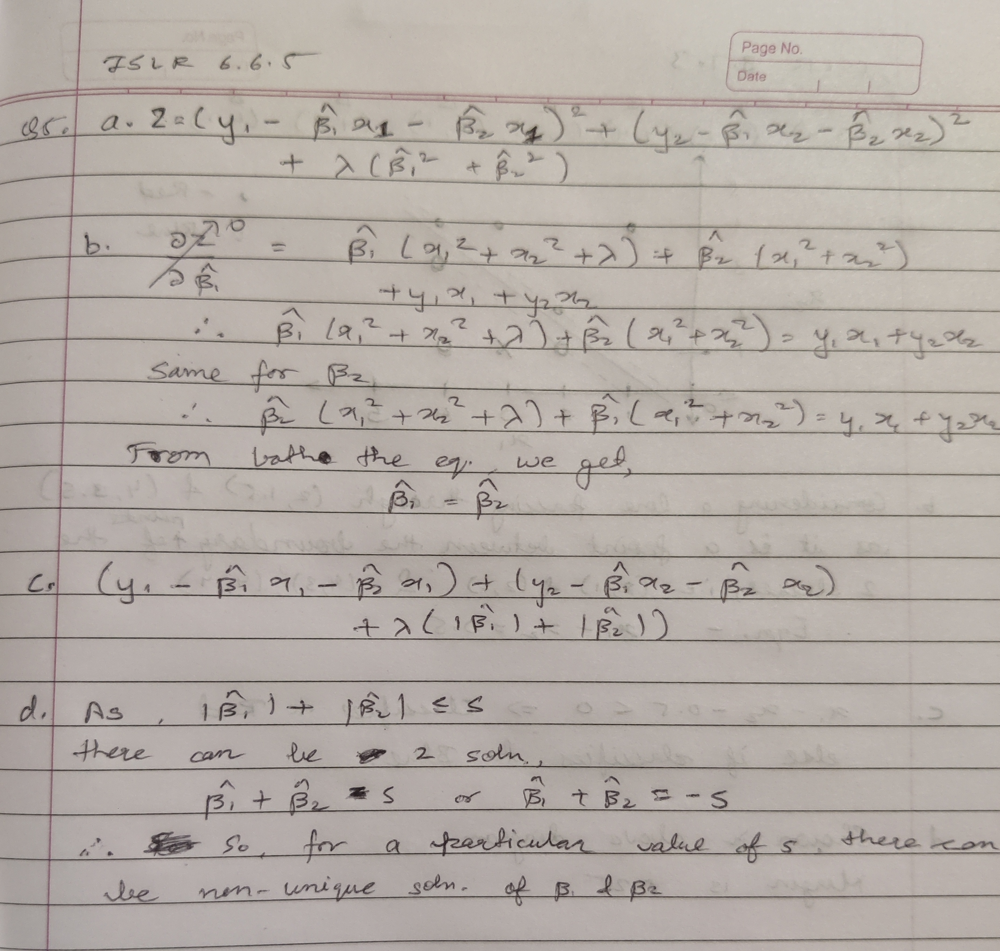

Q4

For majority vote approach, X will be classified as Red because majority votes are for red class among the 10 predictions (6 for Red vs 4 for Green, as probability is more than 0.5 for Red). 
For average probability approach, X will be classified as Green as the average of the 10 probabilities is 0.45.

Q5

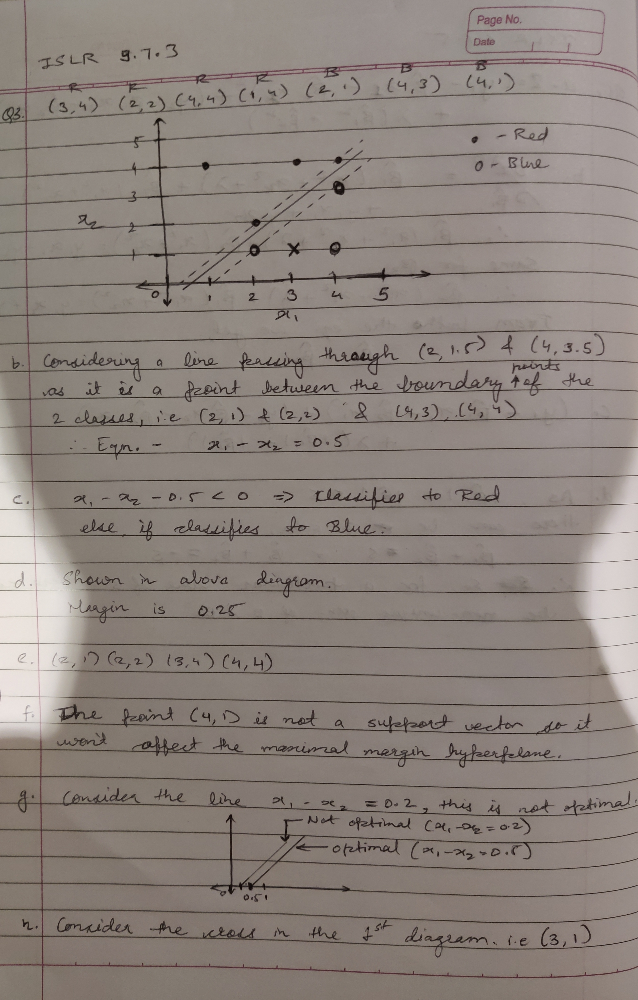